# 01 — Exploratory data analysis

Every section follows the same path: **question → analysis → insight → consequence**. The
notebook only calls functions from `muletrace.analysis.eda`; the logic lives in `src/` and is
tested there. Data: HI-Small after `muletrace data prepare` (all synthetic).

In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

from muletrace.analysis import eda
from muletrace.config import CONFIG_DIR, load_config
from muletrace.data.labels import LabelConfig, confirmations, mule_events

pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(3)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/processed/HI-Small"
labels = load_config(LabelConfig, ROOT / CONFIG_DIR / "labels.yaml")
transactions = pl.scan_parquet(DATA / "transactions.parquet")
mules = mule_events(transactions)
confirmed = confirmations(mules, labels.confirmation_delay)

## 1. How does prevalence move over time?

**Question.** Is the laundering rate stable across days, or does the calendar change the problem?

In [2]:
daily = eda.daily_laundering(transactions)
daily

day,transactions,laundering,laundering_per_10k
date,u32,u32,f64
2022-09-01,1114921,322,2.888
2022-09-02,754449,408,5.408
2022-09-03,207382,391,18.854
2022-09-04,207430,407,19.621
2022-09-05,482650,471,9.759
…,…,…,…
2022-09-14,121,70,5785.124
2022-09-15,46,28,6086.957
2022-09-16,46,26,5652.174


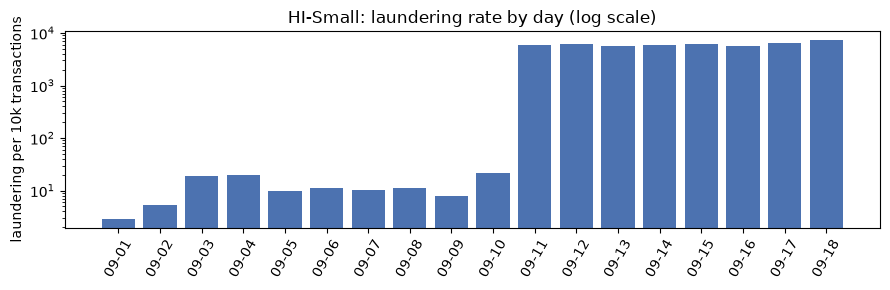

In [3]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar([d.isoformat()[5:] for d in daily["day"]], daily["laundering_per_10k"], color="#4c72b0")
ax.set_ylabel("laundering per 10k transactions")
ax.set_yscale("log")
ax.set_title("HI-Small: laundering rate by day (log scale)")
plt.xticks(rotation=60)
plt.tight_layout()

**Insight.** Traffic drops on 3–4 and 10 September (weekend days) while laundering counts stay
in the same range, so the *rate* rises on those days. After 10 September almost all traffic
stops and what remains is mostly laundering (see the data card for exact tail counts).

**Consequence.** Snapshots stop at 9 September so that no label window depends only on the
tail, and results are reported per snapshot as well as pooled: a single pooled number would
hide the weekday effect.

## 2. Which typologies, and how large are they?

**Question.** What does the ground truth for the copilot's typology task look like?

In [4]:
eda.typology_mix(pl.read_parquet(DATA / "attempts.parquet"))

typology,attempts,median_transactions,max_transactions
str,u32,f64,u32
"""CYCLE""",54,4.000,12
"""GATHER-SCATTER""",51,14.000,28
"""BIPARTITE""",49,4.000,15
"""FAN-OUT""",48,7.000,16
"""SCATTER-GATHER""",44,14.000,32
"""STACK""",43,10.000,30
"""RANDOM""",41,3.000,11
"""FAN-IN""",40,8.000,16


**Insight.** The eight typologies are roughly balanced (40–54 attempts each). Gather-scatter and
scatter-gather attempts are the largest (median 14 transactions); random and cycle attempts are
small (median 3 and 4).

**Consequence.** A typology-accuracy metric will not be dominated by one class, and the gold
case set can be stratified by typology without running out of cases.

## 3. Which payment formats carry laundering?

**Question.** Is laundering spread across formats like ordinary traffic?

In [5]:
eda.format_mix(transactions)

payment_format,transactions,laundering,share_of_transactions,share_of_laundering,laundering_per_10k
str,u32,u32,f64,f64,f64
"""ACH""",600797,4483,0.118,0.866,74.618
"""Cheque""",1864331,324,0.367,0.063,1.738
"""Credit Card""",1323324,206,0.261,0.040,1.557
"""Cash""",490891,108,0.097,0.021,2.200
"""Bitcoin""",146091,56,0.029,0.011,3.833
"""Wire""",171855,0,0.034,0.000,0.000
"""Reinvestment""",481056,0,0.095,0.000,0.000


**Insight.** ACH carries about 12% of all transactions but about 87% of laundering; its laundering
rate is roughly 75 per 10,000 transactions, against at most about 4 for any other format. Wire
and Reinvestment carry none.

**Consequence.** The share of an account's inflow that arrives by ACH is a feature. It also
means the Pix layer, which re-labels ACH and Wire as instant transfers, covers most laundered
money.

## 4. Does laundering happen at night?

**Question.** Brazilian scams are associated with night-time transfers, which is why the night
limit exists. Is that true in AMLworld?

hour,ordinary_share,laundering_share
i8,f64,f64
0,0.086,0.034
1,0.040,0.029
2,0.040,0.032
3,0.040,0.028
4,0.040,0.030
…,…,…
19,0.040,0.045
20,0.040,0.026
21,0.040,0.030


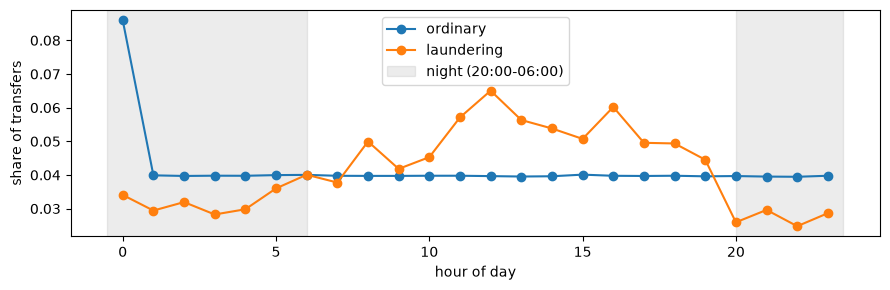

In [6]:
hours = eda.hour_of_day(transactions)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(hours["hour"], hours["ordinary_share"], label="ordinary", marker="o")
ax.plot(hours["hour"], hours["laundering_share"], label="laundering", marker="o")
ax.axvspan(20, 23.5, color="grey", alpha=0.15)
ax.axvspan(-0.5, 6, color="grey", alpha=0.15, label="night (20:00-06:00)")
ax.set_xlabel("hour of day")
ax.set_ylabel("share of transfers")
ax.legend()
plt.tight_layout()
hours

**Insight.** No. Ordinary traffic is flat across hours (with a spike at midnight), while laundering
peaks during business hours (around 11:00–16:00) and is *under*-represented at night.

**Consequence.** A night-activity feature is kept in the feature set because real data may differ,
but it is not expected to help here. Any claim about night-time behaviour from this project would
be a property of the simulator, not of Pix.

## 5. What does a future mule look like at the moment it is scored?

**Question.** At an as-of time, how do accounts that will be confirmed within the horizon differ
from the rest, using only the past?

In [7]:
as_of = datetime(2022, 9, 7)
profile = eda.snapshot_profile(
    transactions, confirmed, as_of, labels.population_lookback, labels.horizon
)
already_active = profile.filter("label")["already_active"].mean()
print(f"scored accounts: {profile.height:,}, positives: {profile['label'].sum():,}")
print(f"positives already active before as-of: {already_active:.1%}")
eda.compare_groups(
    profile,
    ["account_age_hours", "inflow_usd_24h", "distinct_senders_24h", "outflow_count_24h"],
).transpose(include_header=True)

scored accounts: 276,396, positives: 705
positives already active before as-of: 56.2%


column,column_0,column_1
str,f64,f64
"""label""",0.000,1.000
"""accounts""",275691.000,705.000
"""account_age_hours_median""",143.667,143.617
"""inflow_usd_24h_median""",493.260,5635.100
"""distinct_senders_24h_median""",1.000,1.000
"""outflow_count_24h_median""",0.000,0.000
"""account_age_hours_mean""",140.075,138.752
"""inflow_usd_24h_mean""",449787.767,25160233.158
"""distinct_senders_24h_mean""",0.839,2.182


**Insight.** More than half of the positives already received illicit money before the as-of
time: the confirmation delay means the score's job is partly to *find active, unconfirmed mules*,
not only to predict new ones. Future mules have more distinct senders on average and a much
higher median inflow. Account age does not separate the groups at all: in AMLworld almost every
account is active from the first days.

**Consequence.** The young-account rule cannot work on this data, and the rules baseline will be
weak for a reason that is about the simulator, not about the rule. Inflow volume, counterparty
diversity and network features carry the signal.

## 6. Do mules forward money faster?

**Question.** The pass-through rule assumes mules move money on quickly. Do they?

In [8]:
mule_forward = eda.time_to_forward(
    transactions, mules.select("account_id", anchor_at="became_mule_at")
)
control_forward = eda.time_to_forward(transactions, eda.first_inflows(transactions, exclude=mules))
summary = (
    pl.concat(
        [
            mule_forward.select(group=pl.lit("mules, after first illicit inflow"), hours="hours_to_forward"),
            control_forward.select(group=pl.lit("others, after first inflow"), hours="hours_to_forward"),
        ]
    )
    .group_by("group")
    .agg(
        accounts=pl.len(),
        never_forward=pl.col("hours").null_count() / pl.len(),
        median_hours=pl.col("hours").median(),
        forward_within_24h=(pl.col("hours") <= 24).sum() / pl.len(),
    )
    .sort("group")
)
summary

group,accounts,never_forward,median_hours,forward_within_24h
str,u32,f64,f64,f64
"""mules, after first illicit inf…",3984,0.482,13.992,0.331
"""others, after first inflow""",280410,0.455,12.983,0.382


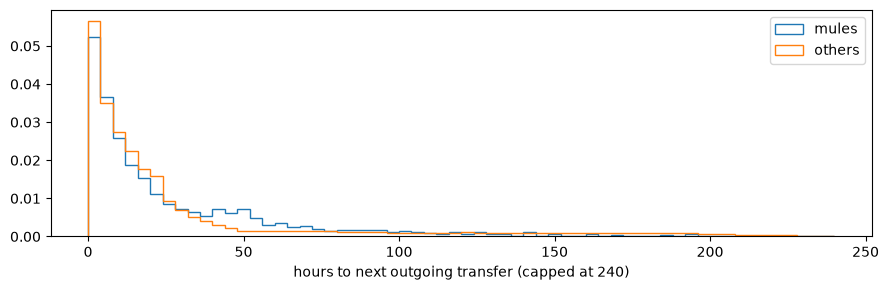

In [9]:
fig, ax = plt.subplots(figsize=(9, 3))
for frame, label in ((mule_forward, "mules"), (control_forward, "others")):
    ax.hist(
        frame["hours_to_forward"].drop_nulls().clip(upper_bound=240),
        bins=60,
        density=True,
        histtype="step",
        label=label,
    )
ax.set_xlabel("hours to next outgoing transfer (capped at 240)")
ax.legend()
plt.tight_layout()

**Insight.** Barely. Mules and other accounts have similar median times to their next outgoing
transfer (about 14 and 13 hours) and similar shares that never send money again (about 48% and
45%). AMLworld's laundering does not look like the fast cash-out of a Brazilian scam mule.

**Consequence.** Pass-through and time-to-forward features stay in the feature set (they are
cheap and they matter on real data), but the model's lift will have to come from elsewhere. The
eval report shows it through feature importance and the ablation.

## 7. Which entity types become mules?

**Question.** Does the entity type matter?

In [10]:
eda.mule_rate_by_entity_type(pl.read_parquet(DATA / "accounts.parquet"), mules)

entity_type,accounts,mules,mules_per_10k
str,u32,u32,f64
"""Sole Proprietorship""",149048,1223,82.054
"""Partnership""",189683,1464,77.181
"""Corporation""",172351,1278,74.151
"""Country""",6692,19,28.392
"""Individual""",740,0,0.000
"""Direct""",67,0,0.000


**Insight.** Sole proprietorships, partnerships and corporations become mules at similar rates
(roughly 74–82 per 10,000 accounts); none of the 740 individuals does.

**Consequence.** Entity type is a weak feature. The Pix layer treats individuals and sole
proprietorships as natural persons for the night limit, so almost every night-limit check involves
sole proprietorships.

## Summary for the design

| Finding | Design consequence |
|---|---|
| Weekend days change the rate | Report per snapshot and pooled; stop snapshots at 9 September |
| ACH carries most laundering | Inflow-by-format features |
| Laundering is a daytime activity here | Night features kept but not expected to help |
| Over half of the positives are already active | The score must find active, unconfirmed mules |
| Account age does not separate mules | The young-account rule cannot work on AMLworld |
| Forwarding speed barely differs | Lift must come from volume, diversity and the network |
